In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load your full dataset
df = pd.read_csv('german_credit_data.csv')

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (1000, 21)

Columns: ['status_account', 'month_duration', 'credit_history', 'purpose', 'credit_amount', 'status_savings', 'years_employment', 'payment_to_income_ratio', 'status_and_sex', 'secondary_obligor', 'residence_since', 'collateral', 'age', 'other_installment_plans', 'housing', 'n_credits', 'job', 'n_guarantors', 'telephone', 'is_foreign_worker', 'target']

First 5 rows:


,status_account,month_duration,credit_history,purpose,credit_amount,status_savings,years_employment,payment_to_income_ratio,status_and_sex,secondary_obligor,...,collateral,age,other_installment_plans,housing,n_credits,job,n_guarantors,telephone,is_foreign_worker,target
0,< 0 DM,6,critical account/ other credits existing (not ...,radio/television,1169,unknown/ no savings account,>= 7 years,4,male : single,none,...,none,67,none,own,2,skilled employee/ official,1,"yes, registered under the customers name",yes,good
1,0 to < 200 DM,48,existing credits paid back duly till now,radio/television,5951,< 100 DM,1 to < 4 years,2,female : divorced/separated/married,none,...,none,22,none,own,1,skilled employee/ official,1,none,yes,bad
2,no checking account,12,critical account/ other credits existing (not ...,education,2096,< 100 DM,4 to < 7 years,2,male : single,none,...,none,49,none,own,1,unskilled - resident,2,none,yes,good
3,< 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,< 100 DM,4 to < 7 years,2,male : single,guarantor,...,car,45,none,for free,1,skilled employee/ official,2,none,yes,good
4,< 0 DM,24,delay in paying off in the past,car (new),4870,< 100 DM,1 to < 4 years,3,male : single,none,...,savings agreement/life insurance,53,none,for free,2,skilled employee/ official,2,none,yes,bad


Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   status_account           1000 non-null   str  
 1   month_duration           1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   credit_amount            1000 non-null   int64
 5   status_savings           1000 non-null   str  
 6   years_employment         1000 non-null   str  
 7   payment_to_income_ratio  1000 non-null   int64
 8   status_and_sex           1000 non-null   str  
 9   secondary_obligor        1000 non-null   str  
 10  residence_since          1000 non-null   int64
 11  collateral               1000 non-null   str  
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   str  
 14  housing                  1000 non-null   str  
 15  n_

,month_duration,credit_amount,payment_to_income_ratio,residence_since,age,n_credits,n_guarantors
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000


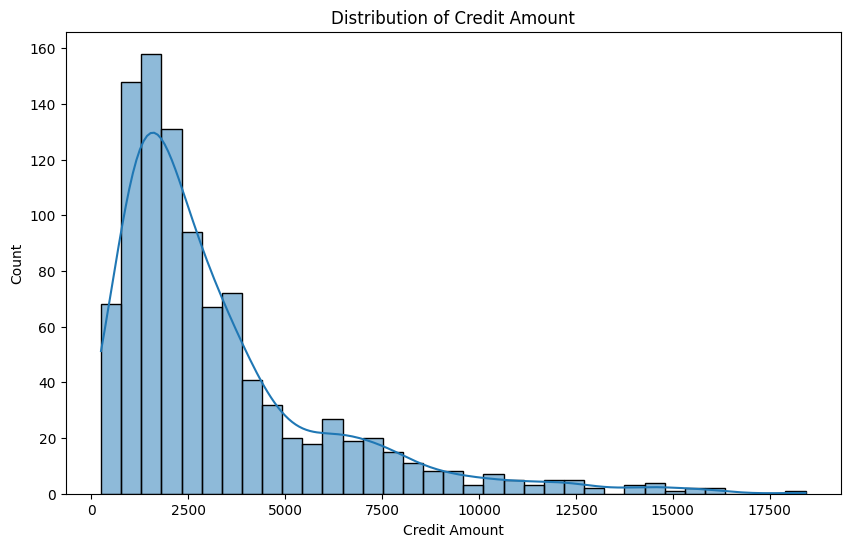

In [6]:
# Basic information
print("Dataset Info:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDescriptive Statistics:")
display(df.describe())

# Target variable distribution
plt.figure(figsize=(10, 6))
sns.histplot(df['credit_amount'], kde=True)
plt.title('Distribution of Credit Amount')
plt.xlabel('Credit Amount')
plt.show()

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   status_account           1000 non-null   str  
 1   month_duration           1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   credit_amount            1000 non-null   int64
 5   status_savings           1000 non-null   str  
 6   years_employment         1000 non-null   str  
 7   payment_to_income_ratio  1000 non-null   int64
 8   status_and_sex           1000 non-null   str  
 9   secondary_obligor        1000 non-null   str  
 10  residence_since          1000 non-null   int64
 11  collateral               1000 non-null   str  
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   str  
 14  housing                  1000 non-null   str  
 15  n_credits       

In [9]:
# Target variable - This is typically the credit risk (good/bad)
target = 'target'

# All features (excluding target)
feature_columns = [
    'status_account', 'month_duration', 'credit_history', 'purpose',
    'credit_amount', 'status_savings', 'years_employment', 
    'payment_to_income_ratio', 'status_and_sex', 'secondary_obligor',
    'collateral', 'residence_since', 'age', 'other_installment_plans',
    'housing', 'n_credits', 'job', 'n_guarantors', 'telephone',
    'is_foreign_worker'
]

X = df[feature_columns]
y = df[target]

print("Target:", target)
print("Number of features:", X.shape[1])
print("\nCategorical Features:")
print(X.select_dtypes(include=['object']).columns.tolist())
print("\nNumerical Features:")
print(X.select_dtypes(include=['int64', 'float64']).columns.tolist())

Target: target
Number of features: 20

Categorical Features:
['status_account', 'credit_history', 'purpose', 'status_savings', 'years_employment', 'status_and_sex', 'secondary_obligor', 'collateral', 'other_installment_plans', 'housing', 'job', 'telephone', 'is_foreign_worker']

Numerical Features:
['month_duration', 'credit_amount', 'payment_to_income_ratio', 'residence_since', 'age', 'n_credits', 'n_guarantors']


In [10]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), 
         categorical_features)
    ])

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numeric_features))
print("Preprocessing pipeline created successfully!")

Categorical features: 13
Numerical features: 7
Preprocessing pipeline created successfully!


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Class distribution in training set:")
print(y_train.value_counts())

Training samples: 800
Testing samples: 200
Class distribution in training set:
target
good    560
bad     240
Name: count, dtype: int64


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Random Forest Classifier Pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200, 
        random_state=42,
        class_weight='balanced'  # Good for imbalanced credit data
    ))
])

rf_pipeline.fit(X_train, y_train)

print("Random Forest Classifier trained successfully!")

Random Forest Classifier trained successfully!


In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

# Predictions
y_pred = rf_pipeline.predict(X_test)
y_pred_proba = rf_pipeline.predict_proba(X_test)[:, 1]

# Metrics
print("Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Performance:
Accuracy: 0.7400
ROC AUC Score: 0.7706

Classification Report:
              precision    recall  f1-score   support

         bad       0.61      0.37      0.46        60
        good       0.77      0.90      0.83       140

    accuracy                           0.74       200
   macro avg       0.69      0.63      0.64       200
weighted avg       0.72      0.74      0.72       200


Confusion Matrix:
[[ 22  38]
 [ 14 126]]


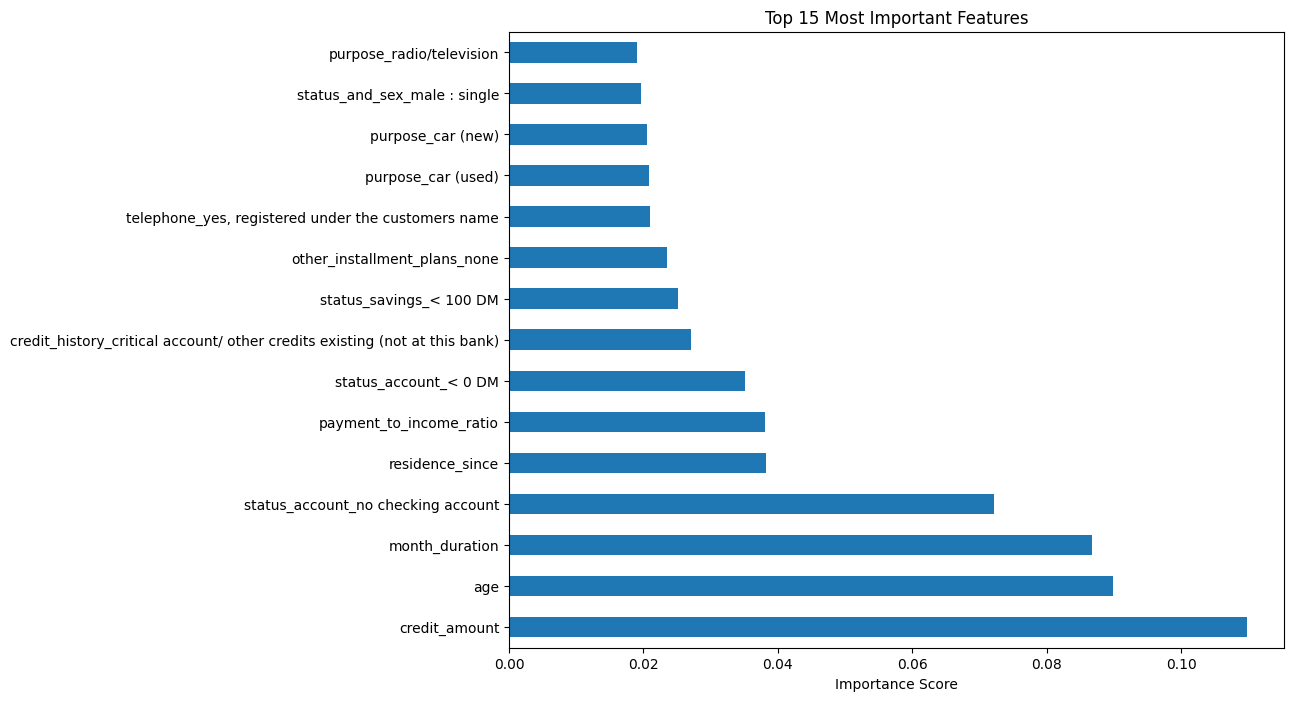

credit_amount                                                                 0.109817
age                                                                           0.089841
month_duration                                                                0.086816
status_account_no checking account                                            0.072171
residence_since                                                               0.038290
payment_to_income_ratio                                                       0.038123
status_account_< 0 DM                                                         0.035145
credit_history_critical account/ other credits existing (not at this bank)    0.027037
status_savings_< 100 DM                                                       0.025215
other_installment_plans_none                                                  0.023577
telephone_yes, registered under the customers name                            0.021048
purpose_car (used)                         

In [14]:
# Extract feature names after preprocessing
cat_feature_names = rf_pipeline.named_steps['preprocessor'] \
    .named_transformers_['cat'].get_feature_names_out(categorical_features)

feature_names = np.concatenate([numeric_features, cat_feature_names])

# Get importance
importances = rf_pipeline.named_steps['classifier'].feature_importances_
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Plot top 15
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))
feat_imp.head(15).plot(kind='barh')
plt.title('Top 15 Most Important Features')
plt.xlabel('Importance Score')
plt.show()

display(feat_imp.head(20))

In [15]:
# Example new applicant
new_data = pd.DataFrame({
    'status_account': ['... < 0 DM'],
    'month_duration': [24],
    'credit_history': ['no credits taken/all credits paid back duly'],
    'purpose': ['car'],
    'credit_amount': [3000],
    'status_savings': ['... < 100 DM'],
    'years_employment': ['1 <= ... < 4 years'],
    'payment_to_income_ratio': [4],
    'status_and_sex': ['male : single'],
    'secondary_obligor': ['none'],
    'collateral': ['real estate'],
    'residence_since': [4],
    'age': [35],
    'other_installment_plans': ['none'],
    'housing': ['own'],
    'n_credits': [2],
    'job': ['skilled employee / official'],
    'n_guarantors': [1],
    'telephone': ['yes, registered under the customers name'],
    'is_foreign_worker': ['no']
})

prediction = rf_pipeline.predict(new_data)
probability = rf_pipeline.predict_proba(new_data)[:, 1]

print("Prediction:", "Good Credit" if prediction[0] == "good" else "Bad Credit")
print(f"Probability of Good Credit: {probability[0]:.4f}")

Prediction: Good Credit
Probability of Good Credit: 0.7800
